# Significant Motif TFs Scatter Plot

In [2]:
import numpy as np
import pandas as pd
import os

In [3]:
# directory and data file settings
modisco_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_modisco_TFs_withLabels.csv"
homer_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
deg_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/pairwise_DE_sites_analysis/out_files/pairwise_DEsites_9_clusters_ordered.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3/sig_motif_res"

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

In [4]:
# load results
modisco_tfs = pd.read_csv(modisco_f)
homer_tfs = pd.read_csv(homer_f)
deg_info = pd.read_csv(deg_f)
print(modisco_tfs.head(), modisco_tfs.shape)
print(homer_tfs.head(), homer_tfs.shape)
print(deg_info.head())

                   Pattern  Seqlet_Count tf_symbol       q_value  \
0   pos_patterns.pattern_1         22453      Ctcf  1.373140e-12   
1  pos_patterns.pattern_21           994    Thap11  6.153510e-08   
2  pos_patterns.pattern_22           475      Rfx5  1.089570e-07   
3  pos_patterns.pattern_22           475      Rfx1  1.089570e-07   
4  pos_patterns.pattern_22           475      Rfx2  1.089570e-07   

   is_expressed  is_deg  is_des  
0          True   False   False  
1          True   False   False  
2          True   False   False  
3          True   False    True  
4          True   False   False   (100, 7)
              target_id tf_symbol       p_value       e_value       q_value  \
0  IRF9.H14CORE.0.PSM.A      Irf9  1.885730e-14  3.007740e-11  5.985070e-11   
1   IRF8.H14CORE.1.SM.B      Irf8  3.919000e-13  6.250800e-10  6.219190e-10   
2    IRF1.H14CORE.0.P.B      Irf1  1.331410e-12  2.123600e-09  1.408580e-09   
3   STAT2.H14CORE.0.P.B     Stat2  6.743940e-11  1.075660e-07 

In [5]:
expressed_modisco_tfs = modisco_tfs.loc[
    modisco_tfs.is_expressed,
    ["tf_symbol", "q_value"]
].copy()
expressed_homer_tfs = homer_tfs.loc[
    homer_tfs.is_expressed,
    ["tf_symbol", "q_value"]
].copy()

In [6]:
# Remove CTCF (generic) to make axis lower
expressed_modisco_tfs = expressed_modisco_tfs.loc[
    expressed_modisco_tfs.tf_symbol != "Ctcf",
].copy()

In [7]:
# change coloring to make yellow lighter:
deg_info.loc[deg_info.cluster==2, "cluster_color"] = "#e0cc8f"

## Final plot — pie-marker scatter of motif enrichment q-values

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


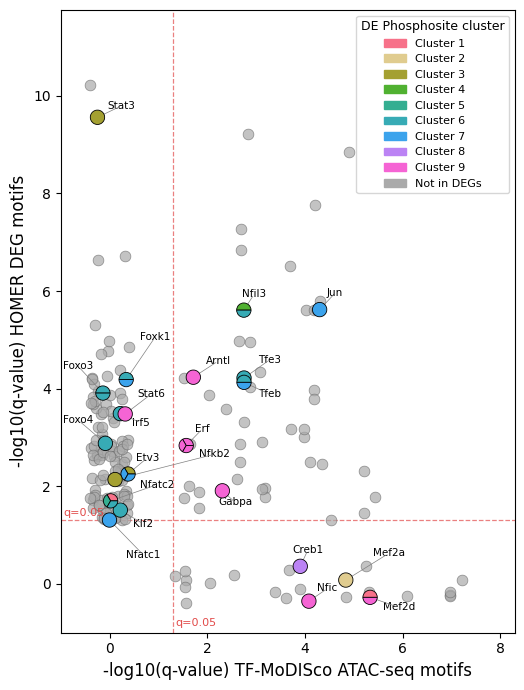

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Wedge
from adjustText import adjust_text

def draw_pie_marker(ax, x, y, colors, size=80, zorder=4):
    n = len(colors)
    angles = np.linspace(0, 360, n + 1)
    fig = ax.get_figure()
    ax_width_inch = ax.get_position().width * fig.get_figwidth()
    ax_xrange = ax.get_xlim()[1] - ax.get_xlim()[0]
    points_per_inch = 72
    radius = (np.sqrt(size) / points_per_inch) * (ax_xrange / ax_width_inch) * 0.5
    for i, color in enumerate(colors):
        wedge = Wedge(
            center=(x, y),
            r=radius,
            theta1=angles[i],
            theta2=angles[i + 1],
            facecolor=color,
            edgecolor="black",
            linewidth=0.6,
            zorder=zorder
        )
        ax.add_patch(wedge)

# Outer merge — keep all TFs from either source
merged = expressed_homer_tfs[["tf_symbol", "q_value"]].merge(
    expressed_modisco_tfs[["tf_symbol", "q_value"]],
    on="tf_symbol",
    how="outer",
    suffixes=("_homer", "_modisco")
)

# Fill missing q_values with 1 → -log10(1) = 0
merged["q_value_homer"] = merged["q_value_homer"].fillna(1)
merged["q_value_modisco"] = merged["q_value_modisco"].fillna(1)

merged["log_q_homer"] = -np.log10(merged["q_value_homer"])
merged["log_q_modisco"] = -np.log10(merged["q_value_modisco"])

# Add jitter for zero points
np.random.seed(42)
merged["plot_x"] = merged["log_q_modisco"].copy()
merged["plot_y"] = merged["log_q_homer"].copy()

homer_zero = merged["log_q_homer"] == 0
modisco_zero = merged["log_q_modisco"] == 0
merged.loc[homer_zero, "plot_y"] = np.random.uniform(-0.4, 0.4, homer_zero.sum())
merged.loc[modisco_zero, "plot_x"] = np.random.uniform(-0.4, 0.4, modisco_zero.sum())

threshold = -np.log10(0.05)

# Build per-gene color list to handle duplicate phosphosites
gene_to_colors = deg_info.groupby("geneSymbol")["cluster_color"].apply(list).to_dict()
merged["in_deg"] = merged["tf_symbol"].isin(gene_to_colors)

fig, ax = plt.subplots(figsize=(8, 7))

# Non-DEG points
non_deg = merged[~merged["in_deg"]]
ax.scatter(
    non_deg["plot_x"], non_deg["plot_y"],
    s=60, alpha=0.7, color="#AAAAAA",
    edgecolors="#666666", linewidths=0.5, zorder=3
)

# Threshold lines
ax.axvline(x=threshold, color="#E24B4A", linestyle="--", linewidth=0.9, alpha=0.7, zorder=2)
ax.axhline(y=threshold, color="#E24B4A", linestyle="--", linewidth=0.9, alpha=0.7, zorder=2)

# Dynamic axis limits — set BEFORE drawing pie markers so radius calc is correct
x_max = merged["log_q_modisco"].max()
y_max = merged["log_q_homer"].max()
ax.set_xlim(-1, x_max * 1.15)
ax.set_ylim(-1, y_max * 1.15)
ax.set_aspect('equal')

# DEG points — pie markers
deg_points = merged[merged["in_deg"]]
for _, row in deg_points.iterrows():
    colors = gene_to_colors.get(row["tf_symbol"], ["#AAAAAA"])
    draw_pie_marker(ax, row["plot_x"], row["plot_y"], colors, size=80, zorder=4)

# Label only DEG-overlapping TFs
label_df = merged[merged["in_deg"]]
texts = [
    ax.text(row["plot_x"], row["plot_y"], row["tf_symbol"], fontsize=7.5)
    for _, row in label_df.iterrows()
]
adjust_text(
    texts,
    x=merged["plot_x"].values,
    y=merged["plot_y"].values,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    expand=(1.5, 2.0),
    force_text=(0.8, 1.0),
    force_points=(0.8, 1.2)
)

# Legend
unique_clusters = deg_info[["cluster", "cluster_color"]].drop_duplicates().sort_values("cluster")
legend_handles = [
    mpatches.Patch(color=row["cluster_color"], label=f"Cluster {int(row['cluster'])}")
    for _, row in unique_clusters.iterrows()
]
legend_handles.append(mpatches.Patch(color="#AAAAAA", label="Not in DEGs"))
ax.legend(handles=legend_handles, fontsize=8, title="DE Phosphosite cluster",
          title_fontsize=9, loc="upper right", framealpha=0.8)

ax.set_xlabel("-log10(q-value) TF-MoDISco ATAC-seq motifs", fontsize=12)
ax.set_ylabel("-log10(q-value) HOMER DEG motifs", fontsize=12)

ax.text(threshold + 0.05, ax.get_ylim()[0] + 0.1, "q=0.05",
        color="#E24B4A", fontsize=8, va="bottom")
ax.text(ax.get_xlim()[0] + 0.05, threshold + 0.05, "q=0.05",
        color="#E24B4A", fontsize=8, va="bottom")

plt.tight_layout()
plt.savefig(f"{out_dir}/figures/motif_based_tf_DES_colored_scatterPlot_qvalues.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{out_dir}/figures/motif_based_tf_DES_colored_scatterPlot_qvalues.svg", dpi=200, bbox_inches="tight")
plt.show()